Homework 4 - 1c

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
N = 200
sigma_e = 1.0
sigma_i_vals = [2.0, 3.0]
dt = 0.02
T = 40.0
steps = int(T/dt)
n_trials = 20

x = np.arange(N)

# Periodic distance around the ring
dist = np.minimum(x, N - x)

In [6]:
def mexican_hat(dist, sigma_e, sigma_i):
    return (np.exp(-dist**2 / (2 * sigma_e**2)) - (sigma_e / sigma_i) * np.exp(-dist**2 / (2 * sigma_i**2)))

def theo_period(N, sigma_e, sigma_i):
    k_star = np.sqrt(4 * np.log(sigma_i / sigma_e) / (sigma_i**2 - sigma_e**2))
    return 2 * np.pi / k_star

def simulate(sigma_i, seed=None):
    rng = np.random.default_rng(seed)

    # Random initial eye preference
    w = rng.normal(0, 0.01, N)

    K = mexican_hat(dist, sigma_e, sigma_i)
    K_hat = np.fft.fft(K)

    for _ in range(steps):
        #using the FFT
        interaction = np.fft.ifft(K_hat * np.fft.fft(w)).real

        w += dt * interaction
        w = np.clip(w, -1, 1)
    return w

def measured_period(w):
    spectrum = np.abs(np.fft.rfft(w))
    spectrum[0] = 0
    mode = np.argmax(spectrum)
    return N / mode

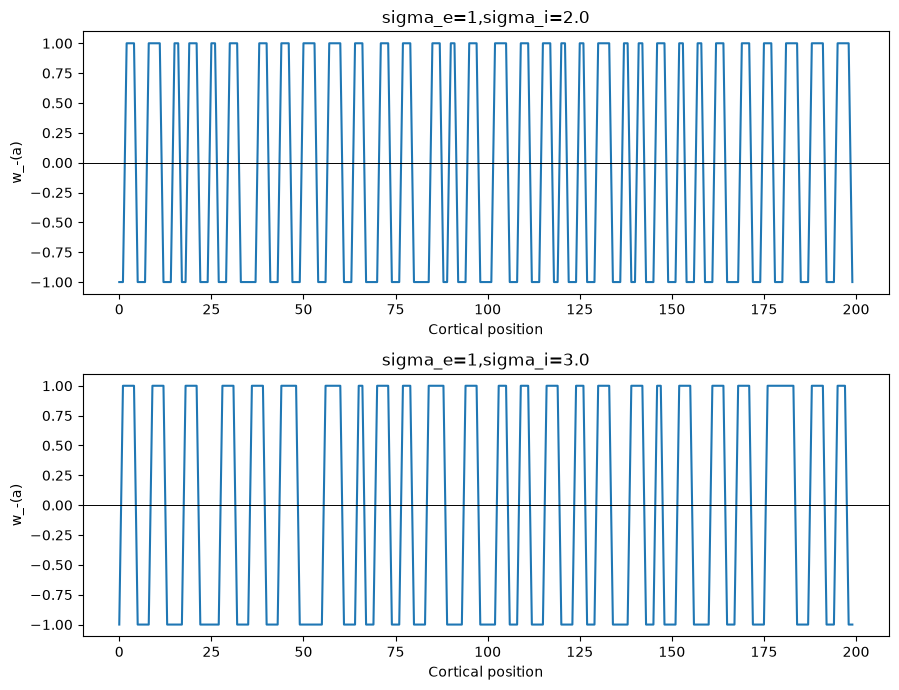

In [10]:
periods = {}
fig, axes = plt.subplots(2, 1, figsize=(9, 7))

for ax, sigma_i in zip(axes, sigma_i_vals):
    trial_periods = []

    for trial in range(n_trials):
        w = simulate(sigma_i, seed=1000 + trial)
        trial_periods.append(measured_period(w))

        if trial == 0:
            ax.plot(np.arange(N), w)
            ax.axhline(0, color="black", linewidth=0.7)
            ax.set_title(f'sigma_e=1,sigma_i={sigma_i}')
            ax.set_xlabel("Cortical position")
            ax.set_ylabel("w_-(a)")

    periods[sigma_i] = trial_periods

plt.tight_layout()
plt.show()

In [16]:
#sigma_i ==2
pred_2 = theo_period(N, sigma_e, 2)
pred_2

np.float64(6.5357851842730055)

In [20]:
periods[2]

[np.float64(6.25),
 np.float64(5.714285714285714),
 np.float64(6.666666666666667),
 np.float64(6.896551724137931),
 np.float64(5.2631578947368425),
 np.float64(7.6923076923076925),
 np.float64(6.666666666666667),
 np.float64(6.896551724137931),
 np.float64(6.25),
 np.float64(6.896551724137931),
 np.float64(6.896551724137931),
 np.float64(6.0606060606060606),
 np.float64(6.451612903225806),
 np.float64(6.666666666666667),
 np.float64(6.0606060606060606),
 np.float64(6.451612903225806),
 np.float64(6.666666666666667),
 np.float64(5.405405405405405),
 np.float64(6.666666666666667),
 np.float64(6.896551724137931)]

In [22]:
np.mean(periods[2])

np.float64(6.470784329421119)

The theoretical wavelength for sigma_i =2 is 6.53, and the measured period is above. The mean measure period is 6.47.

In [24]:
#sigma_i ==3
pred_3 = theo_period(N, sigma_e, 3)
pred_3

np.float64(8.477594506537999)

In [26]:
periods[3]

[np.float64(9.523809523809524),
 np.float64(8.0),
 np.float64(8.333333333333334),
 np.float64(8.695652173913043),
 np.float64(9.523809523809524),
 np.float64(7.6923076923076925),
 np.float64(7.6923076923076925),
 np.float64(8.695652173913043),
 np.float64(7.6923076923076925),
 np.float64(6.896551724137931),
 np.float64(6.896551724137931),
 np.float64(10.0),
 np.float64(10.0),
 np.float64(8.333333333333334),
 np.float64(7.407407407407407),
 np.float64(7.6923076923076925),
 np.float64(8.695652173913043),
 np.float64(8.695652173913043),
 np.float64(8.695652173913043),
 np.float64(6.896551724137931)]

In [28]:
np.mean(periods[3])

np.float64(8.302941996645144)

The theoretical wavelength for sigma_i =2 is 8.48, and the measured period is above. The mean measure period is 8.30.